<a href="https://colab.research.google.com/github/samanthkaturi-spec/Deep-Learning/blob/main/Skill_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       VISIONPORT OBJECT DETECTION SYSTEM

Upload a real photograph...


Saving Screenshot 2026-11-23 at 10.32.21.png to Screenshot 2026-11-23 at 10.32.21.png

Loading YOLOv8 pretrained model...
Model loaded successfully!

Image Acquisition Completed
Original Image Size: (1354, 2036, 3)

Performing Object Detection...

OBJECT DETECTION RESULTS
--------------------------------------------------
1. Object: bus
   Confidence: 94.29%
   Bounding Box: (746, 439, 1415, 1051)
2. Object: person
   Confidence: 86.26%
   Bounding Box: (1107, 842, 1363, 1348)
3. Object: person
   Confidence: 85.06%
   Bounding Box: (1285, 796, 1500, 1345)
4. Object: person
   Confidence: 84.73%
   Bounding Box: (240, 797, 456, 1289)
5. Object: person
   Confidence: 81.59%
   Bounding Box: (515, 822, 720, 1227)
6. Object: person
   Confidence: 74.44%
   Bounding Box: (1741, 814, 1951, 1233)
7. Object: person
   Confidence: 73.95%
   Bounding Box: (122, 838, 262, 1210)
8. Object: traffic light
   Confidence: 72.20%
   Bounding Box: (1597, 389, 1700, 604)
9. Object: person
   Confidence:

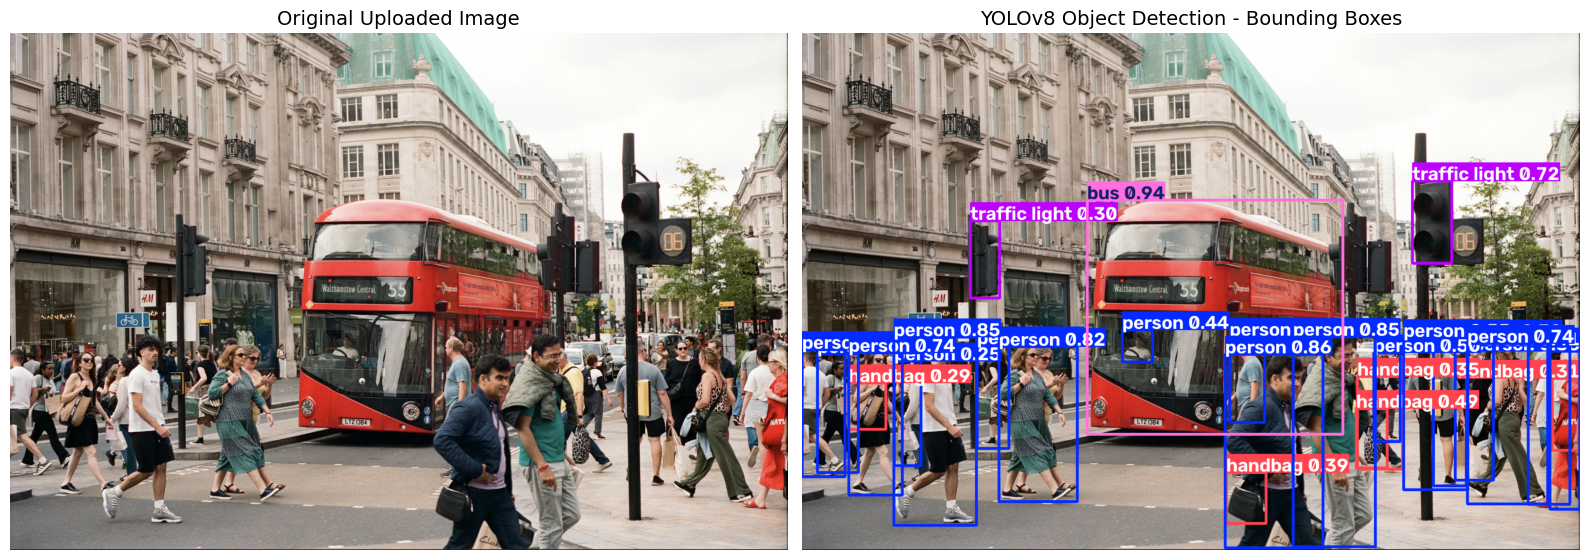


           VISIONPORT SYSTEM REPORT
Image Acquisition       : SUCCESS
Image Preprocessing     : SUCCESS
YOLOv8 Model Loading    : SUCCESS
Object Detection        : SUCCESS
Bounding Box Generation: SUCCESS
Output Visualization    : SUCCESS
Total Objects Detected : 26
VISIONPORT PIPELINE COMPLETED!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# VISIONPORT - DEEP LEARNING OBJECT DETECTION
# Experiment: Project Orientation and Lifecycle Mapping
# Model: YOLOv8
# ============================================================

# 1. INSTALL LIBRARY
!pip install -q ultralytics

# 2. IMPORT LIBRARIES
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

print("=" * 60)
print("       VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 60)

# 3. UPLOAD REAL IMAGE
print("\nUpload a real photograph...")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# 4. LOAD YOLO MODEL
print("\nLoading YOLOv8 pretrained model...")
model = YOLO("yolov8n.pt")

print("Model loaded successfully!")

# 5. IMAGE PREPROCESSING
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded!")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("\nImage Acquisition Completed")
print("Original Image Size:", image_rgb.shape)

# 6. OBJECT DETECTION / INFERENCE
print("\nPerforming Object Detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# 7. DRAW BOUNDING BOXES
output_image = results[0].plot()
output_image = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

# 8. DISPLAY DETECTED OBJECTS
print("\nOBJECT DETECTION RESULTS")
print("-" * 50)

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        x1, y1, x2, y2 = map(int, box.xyxy[0])

        print(f"{i+1}. Object: {object_name}")
        print(f"   Confidence: {confidence*100:.2f}%")
        print(f"   Bounding Box: ({x1}, {y1}, {x2}, {y2})")

else:
    print("No objects detected.")

# 9. DISPLAY ORIGINAL AND DETECTED IMAGE
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Uploaded Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("YOLOv8 Object Detection - Bounding Boxes", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

# 10. SAVE DETECTED IMAGE
output_path = "VisionPort_Detection_Output.jpg"

cv2.imwrite(
    output_path,
    cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)
)

# 11. FINAL SYSTEM REPORT
print("\n" + "=" * 60)
print("           VISIONPORT SYSTEM REPORT")
print("=" * 60)

print("Image Acquisition       : SUCCESS")
print("Image Preprocessing     : SUCCESS")
print("YOLOv8 Model Loading    : SUCCESS")
print("Object Detection        : SUCCESS")
print("Bounding Box Generation: SUCCESS")
print("Output Visualization    : SUCCESS")
print("Total Objects Detected :", len(boxes))
print("=" * 60)
print("VISIONPORT PIPELINE COMPLETED!")

# 12. DOWNLOAD OUTPUT IMAGE
files.download(output_path)
